# Can BCA make the policy better? A test of BCA's mean gate

## Bottom line (written after the run)

- **Yes, when the policy must stay safe.** Hold every gate to the same safety level: it may accept a harmful action at most 5% of the time, in every world. Then BCA's mean gate earns about twice as much as the next-best gate (BCA's cautious average) and about 4.5 times as much as the best gate not built from BCA: 0.084 per situation, against 0.040 and 0.019. It also earned the most at every other cap tried, from 1% to 20%.
- **It keeps its promise.** At its stated 5% level, it accepted at most 0.3% of harmful actions in any world. The two classic guaranteed bounds (Hoeffding, empirical Bernstein) accepted almost nothing, good or harmful. The t-test, the usual shortcut, accepted up to 31% of harmful actions when disasters are rare.
- **It does not win on return alone.** With no safety rule, simply checking the held-out average earns more: 0.158 per situation against 0.045. Two claims were shelved. The mean gate did not beat simple averaging where many candidates compete, and deciding all 20 situations together earned less than deciding each one alone.
- **A lead for the next test (not one of the claims).** BCA's cautious average counts the worst possible gain as one extra try. With no knob at all, it earned 86% of the plain average's return and never lost return in any of the 36 worlds. In the hardest worlds (rare disasters, few good candidates), where the plain average lost return, it earned the most of any real gate.

The details are in the last sections: *What we found*, *What this means for BCA* and *What this does not show*.

**How to run:** open this notebook in the repository's `.venv` and choose Run All. It needs only Python 3, NumPy and Matplotlib, and takes about a minute. Nothing is downloaded and nothing from the repository is imported.

**Why this notebook exists.** [bca_channel_toy.ipynb](bca_channel_toy.ipynb) found one place where BCA helps a policy: as a **gate**. A gate looks at the held-out outcomes of a risky action before the policy may use it. If the outcomes don't pass, the policy keeps a safe action. [The research report](reports/Calibrated%20bounds%20in%20policy%20optimization.md) points to a better gate built from the same parts of BCA. This notebook tests it.

**The idea in one line.** Today's BCA gate asks: "do at least 90% of the risky action's outcomes beat the safe action?" The new **BCA mean gate** asks: "does the risky action beat the safe action *on average*?" It promises to say yes to a harmful action at most 5% of the time.

Everything here is a toy, run on toy seeds only. Each claim's kill rule (the result that would shelve it) was written before the first run and is fingerprinted in the cell that defines it.

## The setup

The policy faces **situations**. In each one it can take a **safe action**, which the log covers well (its value is known, and we call it 0), or one of several **candidate** actions.

- Each candidate has a true **average gain** over the safe action. Above 0 means it is **good**; below 0 means it is **harmful**. Nobody in the story knows these numbers; we use them only to score.
- The log holds a few **tries** of each candidate: between 5 and 100, different for each candidate. A second, separate set of the same number of tries is **held out**.
- **Step 1: the critic proposes.** Looking only at the first set of tries, the critic picks the candidate with the best average. If that average is not above 0, it stays safe. When there are many candidates, the critic is often fooled by one that got lucky on a few tries.
- **Step 2: the gate decides.** Looking only at the held-out tries of the proposed candidate, the gate accepts it or stays safe.
- **The score** is the true average gain of the final choice. Staying safe scores 0.

This mirrors offline reinforcement learning. The critic learns from logged data and likes actions the log barely covers; the safe action is what the log usually did.

## The worlds

Each try's gain follows one of three **shapes**:

| Shape | A typical try | Why it is hard |
|---|---|---|
| Steady | the true average plus noise (spread 1) | the noise is large next to the average |
| Rare disaster | a small gain (0.2 to 0.6), but sometimes a loss of 8 | a few tries often show no disaster |
| Rare jackpot | a small loss (0.1 to 0.4), but sometimes a gain of 8 | a few tries often show no jackpot |

A try's gain always stays inside a known range: −3 to 3 (steady), −8 to 3 (rare disaster), −3 to 8 (rare jackpot). The bottom of the range is the **floor**. Gates may use the range.

A **world** combines one shape, one share of good candidates (10%, 30% or 50%) and one number of candidates per situation (1, 3, 10 or 30). That makes 36 worlds. Each world runs on 200 seeds of 20 situations. Seeds 0–99 are used only to tune knobs (claim 5); every other result uses seeds 100–199. All worlds share the same random numbers, so differences between worlds come from the worlds, not from luck.

## The gates

"Promise 5%" means the gate accepts a harmful proposal at most 5% of the time, in every world.

| Gate | Accepts the proposal when | Promise |
|---|---|---|
| always safe | never | nothing to promise |
| no gate | always (the critic decides alone) | none |
| count rule | it has at least 30 held-out tries (like SPIBB, a count-based safe-improvement method) | none |
| plain average | the held-out average is above 0 | none |
| shrunk average | the held-out average, pulled toward the average of all candidates in the seed's 20 situations, is above 0 | none |
| BCA average | (sum of tries + floor) ÷ (tries + 1) is above 0 | none |
| t-test | the t-test's 95% lower bound on the average is above 0 | 5%, if outcomes are roughly bell-shaped |
| Hoeffding | Hoeffding's 95% lower bound (uses only the range) is above 0 | 5% |
| empirical Bernstein | the empirical Bernstein 95% lower bound (range and spread) is above 0 | 5% |
| **BCA mean gate** | BCA's 95% lower bound on the average is above 0 (see below) | 5% * |
| BCA tail gate (as built) | BCA is 95% sure that at least 90% of tries beat 0 | 5%, about the 90% share |
| split-conformal tail | the 10th-percentile held-out try (with the usual conformal rounding) is above 0 | about the 90% share, only on average over data sets |
| BCA mean gate, shared budget | the 20 situations are decided together, letting more through when many look good (the Benjamini–Hochberg method) | on average, at most 10% of acceptances are harmful |
| oracle gate | the proposal is truly good | scoring reference only |

A **95% lower bound** is a value that the true average is above with 95% confidence. A gate built on one accepts when the bound is above 0.

\* The proof that this bound keeps its promise is in a July 2026 preprint (Vlassis and Thomas) that is not yet peer reviewed. Testing that promise is claim 1.

BCA's tail gate is computed in its exact form here; [bca_channel_toy.ipynb](bca_channel_toy.ipynb) showed that BCA's random sampler gives the same answer.

In [1]:
import math, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt

START = time.perf_counter()
ROOT_SEED, STREAM = 20261014, 41
N_SEEDS, SITUATIONS, CMAX = 200, 20, 30
TUNE_SEEDS, EVAL_SEEDS = np.arange(0, 100), np.arange(100, 200)
SHAPES = ("steady", "rare disaster", "rare jackpot")
GOOD_SHARES = (0.1, 0.3, 0.5)
CANDIDATES = (1, 3, 10, 30)
N_MIN, N_MAX = 5, 100
FLOOR = {"steady": -3.0, "rare disaster": -8.0, "rare jackpot": -3.0}
CEILING = {"steady": 3.0, "rare disaster": 3.0, "rare jackpot": 8.0}
BIG = 8.0
DELTA = 0.05                    # stated level: accept a harmful proposal at most 5% of the time
DRAWS = 10_000                  # BCA's random weightings per decision
TAIL, CONFIDENCE = 0.1, 0.95    # BCA's tail gate as built: at least 90% of tries beat 0, 95% sure
COUNT_NEED = 30
BUDGET = 0.10                   # harm budget of the shared-budget gate
MARGINS = (0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
LEVELS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001)
TAIL_SHARES = (0.5, 0.4, 0.3, 0.2, 0.1, 0.05)
COUNTS = (5, 10, 20, 30, 50, 80, 100)
assert CMAX == max(CANDIDATES) and 0 < DELTA < 1

## How BCA's mean gate works

BCA already gives each held-out try a random weight, plus one extra weight for a worst case. The tail gate uses those weights to check the 90% share. The mean gate uses the same weights differently:

1. Put the extra weight on the **floor**, the worst gain a try can have.
2. For each of 10,000 random weightings, take the weighted average of the tries and the floor.
3. Accept if at most 5% of those averages are below 0.

This is the same calculation as Gaffke's (2005) bound on an average. Of the guaranteed small-sample bounds the research reviewed, it was the tightest. The extra weight on the floor keeps it honest. A harmful candidate that showed no disaster in a few tries still has to pay for the disaster it might be hiding.

The cell below shows, without running the experiment, how much clean evidence each guaranteed gate needs.

In [2]:
def smallest_gain_mean_gate(n, floor=-1.0):
    """Smallest gain the BCA mean gate accepts when all n tries show that same gain (exact; see check 2)."""
    r = DELTA ** (1 / n)
    return -floor * (1 - r) / r

print("Every held-out try shows the same gain g; gains range from -1 to +1. Smallest g each gate accepts:")
print("held-out tries   BCA mean gate   Hoeffding   empirical Bernstein   t-test")
show = lambda v: f"{v:.2f}" if v <= 1 else "never"
for n in (10, 29, 100):
    hoeffding = 2 * math.sqrt(math.log(1 / DELTA) / (2 * n))
    bernstein = 7 * 2 * math.log(2 / DELTA) / (3 * (n - 1))
    print(f"{n:>14}   {show(smallest_gain_mean_gate(n)):>13}   {show(hoeffding):>9}   {show(bernstein):>19}   any g above 0")

n, p_loss = 29, 0.05
clean = (1 - p_loss) ** n
print(f"\nA candidate gains 0.4 on 95% of tries and loses 10 on the rest (true average -0.12, so harmful).")
print(f"With {n} tries, {clean:.0%} of samples contain no loss. The t-test sees no spread in those and accepts,")
print(f"so it accepts this harmful action about {clean:.0%} of the time instead of 5%.")
print(f"Told that the floor is -10, the BCA mean gate puts {(10 / 10.4) ** n:.0%} of its weighted averages below 0")
print("for those same clean samples, far more than 5%, so it refuses.")

Every held-out try shows the same gain g; gains range from -1 to +1. Smallest g each gate accepts:
held-out tries   BCA mean gate   Hoeffding   empirical Bernstein   t-test
            10            0.35        0.77                 never   any g above 0
            29            0.11        0.45                  0.61   any g above 0
           100            0.03        0.24                  0.17   any g above 0

A candidate gains 0.4 on 95% of tries and loses 10 on the rest (true average -0.12, so harmful).
With 29 tries, 23% of samples contain no loss. The t-test sees no spread in those and accepts,
so it accepts this harmful action about 23% of the time instead of 5%.
Told that the floor is -10, the BCA mean gate puts 32% of its weighted averages below 0
for those same clean samples, far more than 5%, so it refuses.


## World and gate code

In [3]:
_erf = np.frompyfunc(math.erf, 1, 1)
def Phi(x): return 0.5 * (1 + np.asarray(_erf(np.asarray(x, dtype=float) / math.sqrt(2)), dtype=float))
def phi(x):
    x = np.asarray(x, dtype=float)
    return np.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def clipped_mean(center, spread, lo=-3.0, hi=3.0):
    """Exact average of clip(center + spread * Z, lo, hi) for a standard normal Z."""
    a, b = (lo - center) / spread, (hi - center) / spread
    return lo * Phi(a) + hi * (1 - Phi(b)) + center * (Phi(b) - Phi(a)) + spread * (phi(a) - phi(b))

def candidates(shape, good, v1, v2):
    """Outcome parameters and exact average gain of each candidate; v1 and v2 are uniform numbers in (0, 1)."""
    if shape == "steady":
        center = np.where(good, 0.05 + 0.45 * v1, -(0.05 + 0.55 * v1))
        return {"center": center, "spread": 1.0, "chance": np.zeros_like(v1), "mean": clipped_mean(center, 1.0)}
    if shape == "rare disaster":
        center = 0.2 + 0.4 * v2
        usual = clipped_mean(center, 0.3)
        even = usual / (usual + BIG)                       # disaster chance that makes the average exactly 0
        chance = np.where(good, 0.7 * even * v1, 1.3 * even + (0.2 - 1.3 * even) * v1)
        return {"center": center, "spread": 0.3, "chance": chance, "mean": (1 - chance) * usual - chance * BIG}
    center = -(0.1 + 0.3 * v2)
    usual = clipped_mean(center, 0.3)                      # the usual small loss (negative)
    even = -usual / (BIG - usual)                          # jackpot chance that makes the average exactly 0
    chance = np.where(good, 1.3 * even + (0.12 - 1.3 * even) * v1, 0.7 * even * v1)
    return {"center": center, "spread": 0.3, "chance": chance, "mean": (1 - chance) * usual + chance * BIG}

def tries(shape, cand, u, z):
    """Gains of tries; u and z hold one uniform and one normal number per try (last axis)."""
    usual = np.clip(cand["center"][..., None] + cand["spread"] * z, -3.0, 3.0)
    if shape == "steady":
        return usual
    big = -BIG if shape == "rare disaster" else BIG
    return np.where(u < cand["chance"][..., None], big, usual)

def shrink(means, variances, counts):
    """Empirical-Bayes shrinkage of each candidate's held-out average toward the average of all candidates in play."""
    pooled = ((counts - 1) * variances).sum() / (counts - 1).sum()
    noise = pooled / counts
    center = means.mean()
    spread = max(0.0, ((means - center) ** 2).mean() - noise.mean())
    return center + spread / (spread + noise) * (means - center)

@lru_cache(maxsize=None)
def t_upper(level, df):
    """t with P(T > t) = level for Student's t with df degrees of freedom (Simpson's rule and bisection)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    w = np.ones(2001)
    w[1:-1:2], w[2:-1:2] = 4, 2
    def tail(t):
        x = np.linspace(0.0, t, 2001)
        return 0.5 - t / 6000 * (w * c * (1 + x * x / df) ** (-(df + 1) / 2)).sum()
    lo, hi = 0.0, 1.0
    while tail(hi) > level:
        hi *= 2
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if tail(mid) > level else (lo, mid)
    return hi

@lru_cache(maxsize=None)
def allowed_below(n, share, confidence=CONFIDENCE):
    """BCA's tail gate as built, in exact form: the most tries that may fall below 0, or -1 if none may."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
                        + x * math.log(share) + (n - x) * math.log1p(-share))
        if cdf > 1 - confidence:
            break
        best = x
    return best

def by_count(fn):
    """fn evaluated at every possible number of tries 0..N_MAX, for lookups by count."""
    return np.array([fn(k) for k in range(N_MAX + 1)])

In [4]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing the results.

Words used. A proposal is harmful when its true average gain over the safe action is below zero, and good when
it is above zero. In a world, a gate's harm rate is the share of harmful proposals it accepts, and its gain is
the true average gain of the final choice per situation (always staying safe scores 0). A world is one
combination of outcome shape (3), share of good candidates (3) and number of candidates (4), so there are 36.
Results use seeds 100-199 (20 situations each) and each gate's stated setting, unless a claim says otherwise.
Pooled means averaged over the 36 worlds with equal weight. Crowded worlds are the 12 worlds with 10 or 30
candidates and 10% or 30% good candidates. A world's allowance on a 5% harm rate is 0.05 plus three standard
errors, 3 * sqrt(0.05 * 0.95 / h), where h is that world's number of harmful proposals.

Claim 1. BCA's mean gate keeps its promise. Shelved if its harm rate is above the allowance in any world.

Claim 2. BCA's mean gate is the tightest of the guaranteed mean gates. Shelved unless, over all worlds together,
the share of good proposals it accepts is at least 0.05 above Hoeffding's and at least 0.05 above empirical
Bernstein's.

Claim 3. A t-test gate is not safe when disasters are rare. Shelved if the t-test gate's harm rate is within the
allowance in every rare-disaster world.

Claim 4. Where many candidates compete and few are good, BCA's mean gate earns more than simple averaging.
Shelved if its pooled gain over the crowded worlds is not above both the plain-average gate's and the
shrunk-average gate's.

Claim 5. At equal harm, BCA's mean gate earns the most. On seeds 0-99, each tunable gate takes the setting from
its fixed grid with the highest pooled gain among settings whose harm rate is at most 0.05 in every world; a
gate with no such setting always stays safe. Shelved if, on seeds 100-199, any other tuned gate's pooled gain
is at least the tuned BCA mean gate's.

Claim 6. Deciding the 20 situations together under a 10% harm budget (Benjamini-Hochberg on BCA's mean-gate
p-values) earns more than deciding each situation alone. Shelved if its pooled gain is not above the
per-situation BCA mean gate's, or if, in any world, the average share of harmful proposals among its
acceptances is above 0.12.
"""
print("Kill rules fingerprint (SHA-256):", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules fingerprint (SHA-256): 50a0f49d678b2205e2dba3af5ea741d8cbc887679127ccdd8612f2c43f93b1d3


## Run

For each seed, the cell below draws every candidate, its tries and BCA's 10,000 random weightings once, and reuses them in all 36 worlds. It records what each gate needs to know about the proposal in each situation.

In [5]:
FIELDS = ("exists", "mu", "n", "mean", "var", "below", "neg", "shrunk", "best")

def run_seed(seed, flip_held=False):
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    n = np.rint(np.exp(rng.uniform(math.log(N_MIN), math.log(N_MAX), (SITUATIONS, CMAX)))).astype(int)
    good_u, v1, v2 = rng.random((3, SITUATIONS, CMAX))
    tr_u, ho_u = rng.random((2, SITUATIONS, CMAX, N_MAX))
    tr_z, ho_z = rng.standard_normal((2, SITUATIONS, CMAX, N_MAX))
    if flip_held:                                                # used only by check 6
        ho_u, ho_z = 1 - ho_u, -ho_z
    weights = rng.standard_exponential((DRAWS, N_MAX + 1))       # one per try, and the last one for the floor
    inside = np.arange(N_MAX) < n[..., None]
    rows = np.arange(SITUATIONS)
    rec = {f: np.zeros((len(SHAPES), len(GOOD_SHARES), len(CANDIDATES), SITUATIONS)) for f in FIELDS}
    for si, shape in enumerate(SHAPES):
        for gi, share in enumerate(GOOD_SHARES):
            cand = candidates(shape, good_u < share, v1, v2)
            train = np.where(inside, tries(shape, cand, tr_u, tr_z), 0.0)
            held = np.where(inside, tries(shape, cand, ho_u, ho_z), 0.0)
            tr_mean, ho_mean = train.sum(-1) / n, held.sum(-1) / n
            ho_var = np.where(inside, (held - ho_mean[..., None]) ** 2, 0.0).sum(-1) / (n - 1)
            ho_below = (inside & (held < 0)).sum(-1)
            picks = []
            for mi, m in enumerate(CANDIDATES):
                j = tr_mean[:, :m].argmax(axis=1)                  # the critic sees training tries only
                picks.append(j)
                shrunk = shrink(ho_mean[:, :m], ho_var[:, :m], n[:, :m])
                values = {"exists": tr_mean[rows, j] > 0, "mu": cand["mean"][rows, j], "n": n[rows, j],
                          "mean": ho_mean[rows, j], "var": ho_var[rows, j], "below": ho_below[rows, j],
                          "shrunk": shrunk[rows, j], "best": np.maximum(0.0, cand["mean"][:, :m].max(axis=1))}
                for f, v in values.items():
                    rec[f][si, gi, mi] = v
            # BCA mean gate: count the weighted averages below 0. A weighted average is below 0 exactly when
            # its weighted sum is, because the weights are positive.
            pairs = sorted({(s, int(j[s])) for j in picks for s in rows})
            index = {p: k for k, p in enumerate(pairs)}
            x = np.stack([held[s, c] for s, c in pairs], axis=1)   # one column per proposal, 0 past its n
            sums = weights[:, :N_MAX] @ x + weights[:, N_MAX:] * FLOOR[shape]
            negative = (sums < 0).sum(axis=0)
            for mi, j in enumerate(picks):
                rec["neg"][si, gi, mi] = negative[[index[(s, int(j[s]))] for s in rows]]
    return rec

records = [run_seed(s) for s in range(N_SEEDS)]
R = {f: np.stack([r[f] for r in records]) for f in FIELDS}     # axes: seed, shape, good share, candidates, situation
EXISTS = R["exists"].astype(bool)
MU, NTRY, MEAN, VAR = R["mu"], R["n"].astype(int), R["mean"], R["var"]
BELOW, NEG, SHRUNK, BEST = R["below"].astype(int), R["neg"].astype(int), R["shrunk"], R["best"]
FLOORS = np.array([FLOOR[s] for s in SHAPES])[None, :, None, None, None]
RANGES = np.array([CEILING[s] - FLOOR[s] for s in SHAPES])[None, :, None, None, None]
HARMFUL, GOOD = EXISTS & (MU < 0), EXISTS & (MU > 0)
print(f"{N_SEEDS} seeds in {time.perf_counter() - START:.0f} s. The critic proposed something in "
      f"{EXISTS.mean():.0%} of situations: {GOOD.sum():,} good proposals and {HARMFUL.sum():,} harmful ones.")

200 seeds in 9 s. The critic proposed something in 75% of situations: 79,355 good proposals and 28,508 harmful ones.


In [6]:
def bh(neg, budget):
    """Benjamini-Hochberg across the 20 situations of each seed and world, on the mean gate's p-values."""
    p = np.where(EXISTS, (neg + 1) / (DRAWS + 1), np.inf)
    out = np.zeros_like(EXISTS)
    flat_p, flat_out = p.reshape(-1, SITUATIONS), out.reshape(-1, SITUATIONS)
    for k in range(flat_p.shape[0]):
        m = np.isfinite(flat_p[k]).sum()
        if m == 0:
            continue
        order = np.argsort(flat_p[k])
        passed = flat_p[k][order] <= budget * np.arange(1, SITUATIONS + 1) / m
        if passed.any():
            flat_out[k, order[:np.nonzero(passed)[0].max() + 1]] = True
    return out

def limit(level):
    return math.floor(Fraction(str(level)) * DRAWS)

def accept(gate, knob=None):
    """Which proposals a gate accepts, at its stated setting or at knob."""
    level = DELTA if knob is None else knob
    margin = 0.0 if knob is None else knob
    if gate == "always safe":
        d = np.zeros_like(EXISTS)
    elif gate == "no gate":
        d = np.ones_like(EXISTS)
    elif gate == "oracle gate":
        d = MU > 0
    elif gate == "count rule":
        d = NTRY >= (COUNT_NEED if knob is None else knob)
    elif gate == "plain average":
        d = MEAN > margin
    elif gate == "shrunk average":
        d = SHRUNK > margin
    elif gate == "BCA average":
        d = (MEAN * NTRY + FLOORS) / (NTRY + 1) > margin
    elif gate == "t-test":
        tq = by_count(lambda k: t_upper(level, k - 1) if k >= 2 else math.inf)[NTRY]
        d = MEAN - tq * np.sqrt(VAR / NTRY) > 0
    elif gate == "Hoeffding":
        d = MEAN - RANGES * np.sqrt(math.log(1 / level) / (2 * NTRY)) > 0
    elif gate == "empirical Bernstein":
        d = (MEAN - np.sqrt(2 * VAR * math.log(2 / level) / NTRY)
             - 7 * RANGES * math.log(2 / level) / (3 * (NTRY - 1))) > 0
    elif gate == "BCA mean gate":
        d = NEG <= limit(level)
    elif gate == "BCA mean gate, shared budget":
        d = bh(NEG, BUDGET if knob is None else knob)
    elif gate == "BCA tail gate":
        share = TAIL if knob is None else knob
        d = BELOW <= by_count(lambda k: allowed_below(k, share) if k >= 1 else -1)[NTRY]
    elif gate == "split-conformal tail":
        share = TAIL if knob is None else knob
        rank = by_count(lambda k: math.floor(Fraction(str(share)) * (k + 1)))[NTRY]
        d = (rank >= 1) & (BELOW < rank)
    else:
        raise KeyError(gate)
    return d & EXISTS

def harm_by_world(d, seeds):
    h = HARMFUL[seeds]
    return (d[seeds] & h).sum(axis=(0, 4)) / np.maximum(h.sum(axis=(0, 4)), 1)

def gain_by_world(d, seeds):
    return np.where(d[seeds], MU[seeds], 0.0).mean(axis=(0, 4))

def good_accepted(d, seeds):
    return (d[seeds] & GOOD[seeds]).sum() / GOOD[seeds].sum()

def false_share_by_world(d, seeds):
    accepted, bad = d[seeds].sum(axis=4), (d[seeds] & HARMFUL[seeds]).sum(axis=4)
    return np.where(accepted > 0, bad / np.maximum(accepted, 1), 0.0).mean(axis=0)

def allowance(seeds):
    h = HARMFUL[seeds].sum(axis=(0, 4))
    return DELTA + 3 * np.sqrt(DELTA * (1 - DELTA) / np.maximum(h, 1))

GATES = ["always safe", "no gate", "count rule", "plain average", "shrunk average", "BCA average", "t-test",
         "Hoeffding", "empirical Bernstein", "BCA mean gate", "BCA tail gate", "split-conformal tail",
         "BCA mean gate, shared budget", "oracle gate"]
DEC = {g: accept(g) for g in GATES}
ORACLE_GAIN = gain_by_world(DEC["oracle gate"], EVAL_SEEDS).mean()

## Results

**How to read the table.** Each row is one gate at its stated setting, on seeds 100–199.
- **gain**: the true average gain per situation, pooled over the 36 worlds. Higher is better; always staying safe scores 0.
- **of oracle**: that gain as a share of the oracle gate's gain (the best any gate can do with the critic's proposals).
- **good accepted**: the share of all good proposals the gate accepted.
- **worst harm**: the highest harm rate over the 36 worlds, where the harm rate is the share of harmful proposals accepted. A gate that promises 5% should stay near or below 5% here.
- **worst disaster harm**: the same, over rare-disaster worlds only.

In [7]:
print(f"{'gate':31}{'gain':>8}{'of oracle':>11}{'good accepted':>15}{'worst harm':>12}{'worst disaster harm':>21}")
for g in GATES:
    gain, harm = gain_by_world(DEC[g], EVAL_SEEDS), harm_by_world(DEC[g], EVAL_SEEDS)
    print(f"{g:31}{gain.mean():8.3f}{gain.mean() / ORACLE_GAIN:11.0%}{good_accepted(DEC[g], EVAL_SEEDS):15.0%}"
          f"{harm.max():12.1%}{harm[1].max():21.1%}")
print(f"\nFor reference, picking the truly best candidate in every situation would gain {BEST[EVAL_SEEDS].mean():.3f}:")
print("the critic's proposals already lose part of that before any gate acts.")

gate                               gain  of oracle  good accepted  worst harm  worst disaster harm
always safe                       0.000         0%             0%        0.0%                 0.0%
no gate                           0.138        66%           100%      100.0%               100.0%
count rule                        0.065        31%            32%       43.2%                12.4%
plain average                     0.158        76%            83%       41.4%                36.2%
shrunk average                    0.151        73%            69%       90.0%                16.4%
BCA average                       0.136        65%            60%       11.8%                 1.7%
t-test                            0.080        39%            44%       31.3%                31.3%
Hoeffding                         0.000         0%             0%        0.0%                 0.0%
empirical Bernstein               0.000         0%             0%        0.0%                 0.0%
BCA mean g

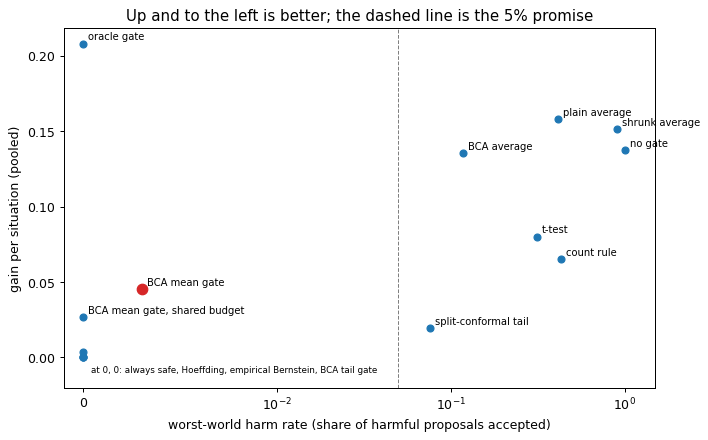

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
near_zero = []
for g in GATES:
    harm = harm_by_world(DEC[g], EVAL_SEEDS).max()
    gain = gain_by_world(DEC[g], EVAL_SEEDS).mean()
    star = g == "BCA mean gate"
    ax.scatter(harm, gain, s=70 if star else 30, color="C3" if star else "C0", zorder=3)
    if harm < 0.002 and gain < 0.01:
        near_zero.append(g)
    else:
        ax.annotate(g, (harm, gain), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.annotate("at 0, 0: " + ", ".join(near_zero), (0, 0), fontsize=7, xytext=(6, -12), textcoords="offset points")
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5); ax.set_ylim(bottom=-0.02)
ax.set_xlabel("worst-world harm rate (share of harmful proposals accepted)")
ax.set_ylabel("gain per situation (pooled)")
ax.set_title("Up and to the left is better; the dashed line is the 5% promise")
fig.tight_layout(); plt.show()

In [9]:
ev = EVAL_SEEDS
allow = allowance(ev)
verdict = lambda alive: "ALIVE" if alive else "SHELVED"

h1 = harm_by_world(DEC["BCA mean gate"], ev)
print(f"Claim 1, BCA's mean gate keeps its promise: worst harm rate {h1.max():.3f}; "
      f"worlds above their allowance: {(h1 > allow).sum()} -> {verdict(not (h1 > allow).any())}")

ga = {g: good_accepted(DEC[g], ev) for g in ("BCA mean gate", "Hoeffding", "empirical Bernstein")}
c2 = ga["BCA mean gate"] - max(ga["Hoeffding"], ga["empirical Bernstein"]) >= 0.05
print(f"Claim 2, tightest guaranteed mean gate: good proposals accepted {ga['BCA mean gate']:.1%} against "
      f"Hoeffding {ga['Hoeffding']:.1%} and empirical Bernstein {ga['empirical Bernstein']:.1%} -> {verdict(c2)}")

ht = harm_by_world(DEC["t-test"], ev)
c3 = bool((ht[1] > allow[1]).any())
print(f"Claim 3, the t-test is unsafe with rare disasters: worst rare-disaster harm rate {ht[1].max():.3f} "
      f"-> {verdict(c3)}")

crowded = np.zeros((len(SHAPES), len(GOOD_SHARES), len(CANDIDATES)), bool)
crowded[:, :2, 2:] = True
gc = {g: gain_by_world(DEC[g], ev)[crowded].mean() for g in ("BCA mean gate", "plain average", "shrunk average")}
c4 = gc["BCA mean gate"] > max(gc["plain average"], gc["shrunk average"])
print(f"Claim 4, crowded worlds: gain {gc['BCA mean gate']:.4f} against plain average {gc['plain average']:.4f} "
      f"and shrunk average {gc['shrunk average']:.4f} -> {verdict(c4)}")

TUNABLE = {"plain average": MARGINS, "shrunk average": MARGINS, "BCA average": MARGINS, "t-test": LEVELS,
           "Hoeffding": LEVELS, "empirical Bernstein": LEVELS, "BCA mean gate": LEVELS,
           "BCA tail gate": TAIL_SHARES, "split-conformal tail": TAIL_SHARES, "count rule": COUNTS}
FRONTIER, TUNED = {}, {}
for g, grid in TUNABLE.items():
    points = []
    for k in grid:
        d = accept(g, k)
        points.append((k, harm_by_world(d, TUNE_SEEDS).max(), gain_by_world(d, TUNE_SEEDS).mean(), d))
    FRONTIER[g] = points
    qualified = [p for p in points if p[1] <= DELTA]
    if qualified:
        k, _, tune_gain, d = max(qualified, key=lambda p: p[2])
        TUNED[g] = (k, tune_gain, gain_by_world(d, ev).mean(), harm_by_world(d, ev).max())
    else:
        TUNED[g] = (None, 0.0, 0.0, 0.0)
best_rival = max((g for g in TUNED if g != "BCA mean gate"), key=lambda g: TUNED[g][2])
c5 = TUNED["BCA mean gate"][2] > TUNED[best_rival][2]
print(f"Claim 5, at equal harm: tuned BCA mean gate gains {TUNED['BCA mean gate'][2]:.4f}; best tuned rival "
      f"{best_rival} gains {TUNED[best_rival][2]:.4f} -> {verdict(c5)}")

gb = gain_by_world(DEC["BCA mean gate, shared budget"], ev).mean()
gm = gain_by_world(DEC["BCA mean gate"], ev).mean()
fs = false_share_by_world(DEC["BCA mean gate, shared budget"], ev)
c6 = gb > gm and fs.max() <= 0.12
print(f"Claim 6, shared 10% harm budget: gain {gb:.4f} against {gm:.4f} deciding alone; worst average harmful "
      f"share of acceptances {fs.max():.3f} -> {verdict(c6)}")

Claim 1, BCA's mean gate keeps its promise: worst harm rate 0.003; worlds above their allowance: 0 -> ALIVE
Claim 2, tightest guaranteed mean gate: good proposals accepted 17.4% against Hoeffding 0.0% and empirical Bernstein 0.0% -> ALIVE
Claim 3, the t-test is unsafe with rare disasters: worst rare-disaster harm rate 0.313 -> ALIVE
Claim 4, crowded worlds: gain 0.0567 against plain average 0.1829 and shrunk average 0.1625 -> SHELVED
Claim 5, at equal harm: tuned BCA mean gate gains 0.0845; best tuned rival BCA average gains 0.0400 -> ALIVE
Claim 6, shared 10% harm budget: gain 0.0270 against 0.0453 deciding alone; worst average harmful share of acceptances 0.000 -> SHELVED


### Equal harm: what each gate earns once tuned to the same safety level

Each gate has one knob: a margin for the averages, a confidence level for the bounds, a share for the tail gates, and a count for the count rule. The chart shows every knob setting on seeds 0–99. Each point is one setting: how often the gate accepted a harmful proposal in its worst world (left–right) and how much it gained (up–down). The table then takes each gate's best setting that stays at or below 5% harm in every world, and scores it on the fresh seeds 100–199.

gate                      chosen knob  gain, seeds 0-99  gain, seeds 100-199  worst harm, 100-199
BCA mean gate                     0.2            0.0864               0.0845                 2.3%
BCA average                       0.5            0.0410               0.0400                 3.8%
shrunk average                    0.5            0.0165               0.0187                 1.6%
Hoeffding                         0.5            0.0167               0.0174                 0.1%
BCA tail gate                     0.2            0.0187               0.0172                 2.9%
plain average                     1.5            0.0061               0.0070                 0.8%
empirical Bernstein               0.5            0.0061               0.0061                 0.0%
split-conformal tail             0.05            0.0064               0.0056                 0.3%
count rule                        100            0.0001               0.0003                 0.2%
t-test              

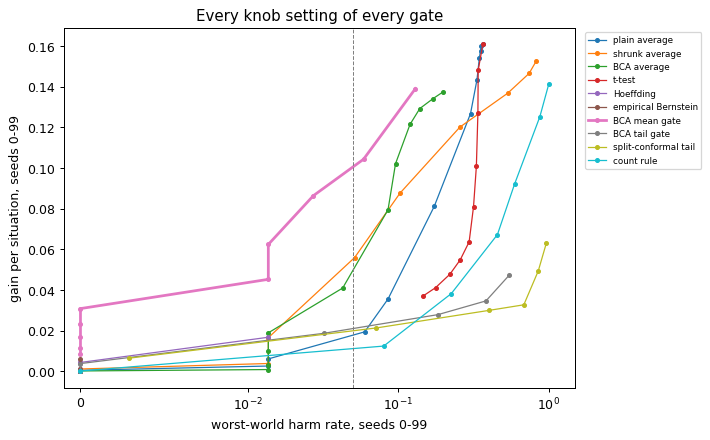

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (g, points) in enumerate(FRONTIER.items()):
    xs, ys = [p[1] for p in points], [p[2] for p in points]
    ax.plot(xs, ys, marker="o", ms=3, lw=2.2 if g == "BCA mean gate" else 1, color=f"C{i}", label=g)
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5)
ax.set_xlabel("worst-world harm rate, seeds 0-99")
ax.set_ylabel("gain per situation, seeds 0-99")
ax.set_title("Every knob setting of every gate")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

print(f"{'gate':24}{'chosen knob':>13}{'gain, seeds 0-99':>18}{'gain, seeds 100-199':>21}{'worst harm, 100-199':>21}")
for g, (k, tune_gain, eval_gain, eval_harm) in sorted(TUNED.items(), key=lambda kv: -kv[1][2]):
    print(f"{g:24}{'none' if k is None else str(k):>13}{tune_gain:18.4f}{eval_gain:21.4f}{eval_harm:21.1%}")

### Where each gate earns its gain

In [11]:
key = ["plain average", "shrunk average", "t-test", "Hoeffding", "empirical Bernstein", "BCA mean gate",
       "BCA tail gate", "BCA mean gate, shared budget", "oracle gate"]
print("Gain per situation by outcome shape (seeds 100-199, pooled over the other two factors)")
print(f"{'gate':31}" + "".join(f"{s:>15}" for s in SHAPES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:15.4f}" for v in gain_by_world(DEC[g], ev).mean(axis=(1, 2))))

print("\nGain per situation by number of candidates (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{m:>10}" for m in CANDIDATES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:10.4f}" for v in gain_by_world(DEC[g], ev).mean(axis=(0, 1))))

print("\nHarm rate by outcome shape, worst over the other factors (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{s:>15}" for s in SHAPES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:15.1%}" for v in harm_by_world(DEC[g], ev).max(axis=(1, 2))))

bins = [(5, 9), (10, 19), (20, 39), (40, 69), (70, 100)]
print("\nShare of good proposals accepted, by number of held-out tries (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{f'{a}-{b}':>9}" for a, b in bins))
for g in key:
    row = []
    for a, b in bins:
        sel = GOOD[ev] & (NTRY[ev] >= a) & (NTRY[ev] <= b)
        row.append((DEC[g][ev] & sel).sum() / max(sel.sum(), 1))
    print(f"{g:31}" + "".join(f"{v:9.0%}" for v in row))

Gain per situation by outcome shape (seeds 100-199, pooled over the other two factors)
gate                                    steady  rare disaster   rare jackpot
plain average                           0.1755         0.0951         0.2038
shrunk average                          0.1616         0.0765         0.2156
t-test                                  0.0993         0.0843         0.0567
Hoeffding                               0.0000         0.0000         0.0001
empirical Bernstein                     0.0000         0.0000         0.0000
BCA mean gate                           0.0540         0.0138         0.0681
BCA tail gate                           0.0000         0.0099         0.0000
BCA mean gate, shared budget            0.0370         0.0032         0.0407
oracle gate                             0.1987         0.1565         0.2690

Gain per situation by number of candidates (seeds 100-199)
gate                                    1         3        10        30
plain avera

## Information only (written after the run; not part of the claims)

These answer two questions the claims did not ask. They guide the next test; they are not findings.

**1. Does the winner depend on how strict the safety level is?** Each gate is tuned on seeds 0–99 to its best setting whose worst-world harm rate stays under a cap, then scored on seeds 100–199. A wider cap allows more harm.

**2. Does any gate lose return?** A gate loses return in a world when its gain there is below 0, which is worse than always staying safe.

In [12]:
CAPS = (0.01, 0.02, 0.05, 0.1, 0.2, 1.0)
print("1. Gain per situation on seeds 100-199, after tuning on seeds 0-99 to each cap on worst-world harm")
print(f"{'gate':22}" + "".join(f"{f'cap {c:.0%}':>10}" for c in CAPS))
held = True
for g, points in FRONTIER.items():
    cells = []
    for cap in CAPS:
        ok = [p for p in points if p[1] <= cap]
        if not ok:
            cells.append(f"{'none':>10}")
            continue
        d = max(ok, key=lambda p: p[2])[3]
        held &= bool(harm_by_world(d, ev).max() <= cap)
        cells.append(f"{gain_by_world(d, ev).mean():10.3f}")
    print(f"{g:22}" + "".join(cells))
print("On seeds 100-199, every tuned gate stayed within its cap:", held)

print("\n2. Worlds (of 36) where each gate loses return at its stated setting, seeds 100-199")
print(f"{'gate':31}{'worlds below 0':>16}{'lowest world gain':>19}")
for g in GATES:
    gw = gain_by_world(DEC[g], ev)
    print(f"{g:31}{(gw < 0).sum():16d}{gw.min():19.4f}")

print("\nThe hardest worlds: rare disasters and 10% good candidates. Gain by number of candidates, seeds 100-199")
print(f"{'gate':31}" + "".join(f"{m:>10}" for m in CANDIDATES))
for g in ("no gate", "plain average", "t-test", "shrunk average", "BCA mean gate", "BCA average", "oracle gate"):
    print(f"{g:31}" + "".join(f"{v:10.4f}" for v in gain_by_world(DEC[g], ev)[1, 0]))

1. Gain per situation on seeds 100-199, after tuning on seeds 0-99 to each cap on worst-world harm
gate                      cap 1%    cap 2%    cap 5%   cap 10%   cap 20%  cap 100%
plain average              0.001     0.007     0.007     0.036     0.078     0.158
shrunk average             0.001     0.019     0.019     0.056     0.087     0.151
BCA average                0.000     0.021     0.040     0.098     0.136     0.136
t-test                      none      none      none      none     0.040     0.158
Hoeffding                  0.005     0.017     0.017     0.017     0.017     0.017
empirical Bernstein        0.006     0.006     0.006     0.006     0.006     0.006
BCA mean gate              0.030     0.061     0.084     0.103     0.137     0.137
BCA tail gate              0.003     0.003     0.017     0.017     0.027     0.046
split-conformal tail       0.006     0.006     0.006     0.019     0.019     0.062
count rule                 0.000     0.000     0.000     0.011     0.01

## Checks

In [13]:
# 1. The exact average gains match simulation, sit inside the stated range, and have the intended sign.
rng = np.random.default_rng([ROOT_SEED, 999])
for shape in SHAPES:
    good = rng.random(6) < 0.5
    cand = candidates(shape, good, rng.random(6), rng.random(6))
    sim = tries(shape, cand, rng.random((6, 200_000)), rng.standard_normal((6, 200_000)))
    se = sim.std(axis=1) / math.sqrt(sim.shape[1])
    assert np.all(np.abs(sim.mean(axis=1) - cand["mean"]) < 5 * se), shape
    assert np.all((cand["mean"] > 0) == good), shape
    assert sim.min() >= FLOOR[shape] and sim.max() <= CEILING[shape], shape
# 2. The mean gate's sampler matches the exact answer for identical tries: with n tries of gain g and floor a,
#    the chance that a weighted average is below 0 is (-a / (g - a)) ** n.
w = np.random.default_rng([ROOT_SEED, 998]).standard_exponential((DRAWS, N_MAX + 1))
for n_, g_, a_ in ((10, 0.35, -1.0), (29, 0.11, -1.0), (29, 0.4, -10.0), (100, 0.03, -1.0)):
    estimate = ((w[:, :n_] * g_).sum(axis=1) + w[:, N_MAX] * a_ < 0).mean()
    exact = (-a_ / (g_ - a_)) ** n_
    assert abs(estimate - exact) < 4 * math.sqrt(exact * (1 - exact) / DRAWS), (n_, g_, a_, estimate, exact)
# 3. Student's t quantiles match published tables.
for level, df, want in ((0.05, 4, 2.1318), (0.05, 9, 1.8331), (0.01, 29, 2.4620), (0.005, 99, 2.6264)):
    assert abs(t_upper(level, df) - want) < 1e-3, (level, df)
# 4. BCA's tail gate cannot accept anything below 29 tries.
assert allowed_below(28, TAIL) == -1 and allowed_below(29, TAIL) == 0
# 5. Gates accept only real proposals, and none gains more than the oracle gate in any world.
oracle_by_world = gain_by_world(DEC["oracle gate"], EVAL_SEEDS)
for g, d in DEC.items():
    assert not (d & ~EXISTS).any(), g
    assert np.all(gain_by_world(d, EVAL_SEEDS) <= oracle_by_world + 1e-12), g
# 6. The critic never sees held-out tries: rerunning seed 0 with different held-out tries changes no proposal.
same, flipped = run_seed(0), run_seed(0, flip_held=True)
for f in ("exists", "mu", "n", "best"):
    assert np.array_equal(same[f], flipped[f]), f
assert not np.array_equal(same["mean"], flipped["mean"])
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

All checks passed. Notebook seconds: 11.7


## What we found (written after the run)

**Claim 1, alive: BCA's mean gate keeps its promise.** Its worst harm rate in any world was 0.3%, far under 5%. The promise held with room to spare, which also shows the gate is cautious in these worlds.

**Claim 2, alive: it is the tightest guaranteed mean gate.** It accepted 17.4% of good proposals. Hoeffding and empirical Bernstein accepted none, because with a wide range (−8 to 3, for example) they need far more tries.

**Claim 3, alive: the t-test is not safe when disasters are rare.** In one rare-disaster world it accepted 31% of harmful proposals. Many small samples contain no disaster, so the t-test sees a steady small gain and accepts. Practical safe-improvement methods often use the t-test anyway, because the guaranteed bounds they had were too loose. BCA's mean gate is a guaranteed bound that still accepts.

**Claim 4, shelved.**

- **The idea.** Where many candidates compete and few are good, the critic is often fooled by a lucky candidate, so a cautious gate should earn more than simply checking the held-out average.
- **What we tested (and the kill rule).** Pooled gain over the 12 crowded worlds (10 or 30 candidates, 10% or 30% good). Shelved if BCA's mean gate did not earn more than both the plain-average gate and the shrunk-average gate.
- **What happened.** 0.057 per situation, against 0.183 for the plain average and 0.163 for the shrunk average.
- **Why.** The held-out tries are fresh, so their average is an honest estimate of a proposal's gain, however lucky the critic's training tries were. After that, extra caution mostly turns good candidates away. The mean gate accepted 1%, 5% and 17% of good proposals with 5–9, 10–19 and 20–39 tries; the plain average accepted 71%, 80% and 89%.

**Claim 5, alive: at equal harm, BCA's mean gate earns the most.** Each gate was tuned on seeds 0–99 to its best setting with at most 5% harm in every world. On seeds 100–199 the mean gate earned 0.084 per situation, at a 20% setting with a worst harm rate of 2.3%. Next came BCA's cautious average (0.040), the shrunk average (0.019), Hoeffding (0.017) and BCA's tail gate (0.017). No t-test setting stayed within 5% harm in every world.

**Claim 6, shelved.**

- **The idea.** Deciding the 20 situations together, with a shared budget of 10% harmful acceptances, should let more good candidates through than deciding each one alone at 5%.
- **What we tested (and the kill rule).** Pooled gain, against the mean gate deciding each situation alone. Shelved if it did not earn more, or if in any world more than 12% of its acceptances were harmful on average.
- **What happened.** 0.027 per situation, against 0.045. Harm was not the problem: in every world, under 0.1% of its acceptances were harmful on average.
- **Why.** Deciding together lets more through only when many situations look clearly good at once. Here few proposals pass at all, and then the shared bar is stricter than 5% per situation.

**Information only.** The mean gate earned the most at every harm cap from 1% to 20%. At 10% and 20%, BCA's cautious average came close. With no cap, the plain average earned the most. Three gates lost return in some worlds: no gate (5 worlds), the plain average (4) and the t-test (4). All four of those plain-average and t-test worlds are the hardest ones, with rare disasters and 10% good candidates. There, BCA's cautious average earned 0.008 to 0.048 per situation, about 40% of what the oracle gate earned.

## What this means for BCA

1. **BCA helps the policy as a certificate on a deviation's average gain, when the policy must stay safe.** Asking about the average instead of the 90% share uses the same random weights plus one extra weight on the worst case. At the same 5% promise, it took the share of good actions accepted from 1% to 17%. It was the best gate at every safety level from 1% to 20%.
2. **It is not a return booster on its own.** If fresh held-out outcomes exist and no safety level is required, the plain held-out average earns more. Caution costs return whenever the evidence it checks is already honest.
3. **BCA's cautious average may be the tool for return.** It is (sum of tries + worst case) ÷ (tries + 1), with no knob. It gave up 14% of the plain average's pooled return and never lost return in any world. It needs its own pre-registered test before it counts.
4. **What it needs in practice.** It needs held-out outcomes of the deviation itself, measured against the fallback, and a known worst case for each outcome (the floor). A wrong floor breaks the promise. In this repository's step 1, the certificate compares how much the critic over-predicts in two groups of rows, using the 5% quantile of BCA's posterior. A mean-gate version would instead put a 95% lower bound on the deviation's average gain. That is a new design and needs its own pre-registration, approved at your terminal.

## What this does not show

- Each gate here gets real, independent held-out tries of the proposed action. In offline reinforcement learning, the outcomes of an unlogged deviation usually have to be estimated, and the errors of that estimate are not modelled here.
- The floor is known exactly. Real tasks need a declared worst case; if outcomes can fall below it, the promise is void.
- There is one decision per situation, with no knock-on effects over time.
- The critic is a simple "best training average" rule, not a trained network.
- The mean gate's guarantee rests on a 2026 preprint. No world broke it here, which supports the proof but does not replace it.
- Everything ran on toy seeds. No production code, host or ThrusterChain run was touched.

## Changes after the first run

- Added: the bottom line, the information-only section and every section after the checks.
- Figure layout only: the horizontal axes no longer show negative harm rates, and the gates sitting at (0, 0) share one label.
- Clearer wording in the gates table: the count rule, split-conformal and shared-budget rows, and a sentence defining a 95% lower bound.
- No code that computes a claim changed. The kill rules are unchanged; the fingerprint printed above matches the one recorded before the first run, `50a0f49d…b1d3`. Rerunning reproduces every number exactly.